# 02 · Exploratory Analysis, Segmentation & Risk
**Business questions**
1. How big is the loan book vs the deposit base? Is lending funded by deposits?
2. Which customer groups (relationship type, nationality, income, age) hold the most loans and deposits?
3. Does the bank's **Risk Weighting** actually capture affordability risk?
4. Does the **Loyalty** programme reflect customer value?
5. Which segments should the bank target for growth or review?

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="crest")
IMG = "../images/"
df = pd.read_csv("../data/processed/banking_clean.csv", parse_dates=["joined_bank"])
M = 1e6
def save(name): plt.tight_layout(); plt.savefig(IMG + name, dpi=150, bbox_inches="tight"); plt.show()
df.shape

(3000, 41)

## 1. Headline KPIs

In [2]:
kpi = pd.Series({
    "Total clients (rows)": len(df),
    "Distinct Client IDs (misleading)": df.client_id.nunique(),
    "Total loans ($M)": df.total_loan.sum() / M,
    "  of which Bank Loans ($M)": df.bank_loans.sum() / M,
    "  of which Business Lending ($M)": df.business_lending.sum() / M,
    "  of which Credit Card Balance ($M)": df.credit_card_balance.sum() / M,
    "Total deposits ($M)": df.total_deposit.sum() / M,
    "Loan-to-deposit ratio (book)": df.total_loan.sum() / df.total_deposit.sum(),
    "Funding gap: loans - deposits ($M)": (df.total_loan.sum() - df.total_deposit.sum()) / M,
    "Est. fee revenue ($M)": df.est_fee_revenue.sum() / M,
    "Avg tenure (years)": df.tenure_years.mean(),
})
kpi.round(2)

Total clients (rows)                  3,000.00
Distinct Client IDs (misleading)      2,940.00
Total loans ($M)                      4,383.97
  of which Bank Loans ($M)            1,774.16
  of which Business Lending ($M)      2,600.28
  of which Credit Card Balance ($M)       9.53
Total deposits ($M)                   3,766.34
Loan-to-deposit ratio (book)              1.16
Funding gap: loans - deposits ($M)      617.63
Est. fee revenue ($M)                   158.19
Avg tenure (years)                       11.38
dtype: float64

**Reading:** the bank has lent more than it holds in deposits: a book-level loan-to-deposit ratio of about **1.16**, i.e. a funding gap of roughly **$0.6B** that must come from other sources (wholesale funding, capital). Business lending is the largest part of the loan book.

*(The dataset doesn't state a currency; amounts are shown as $.)*

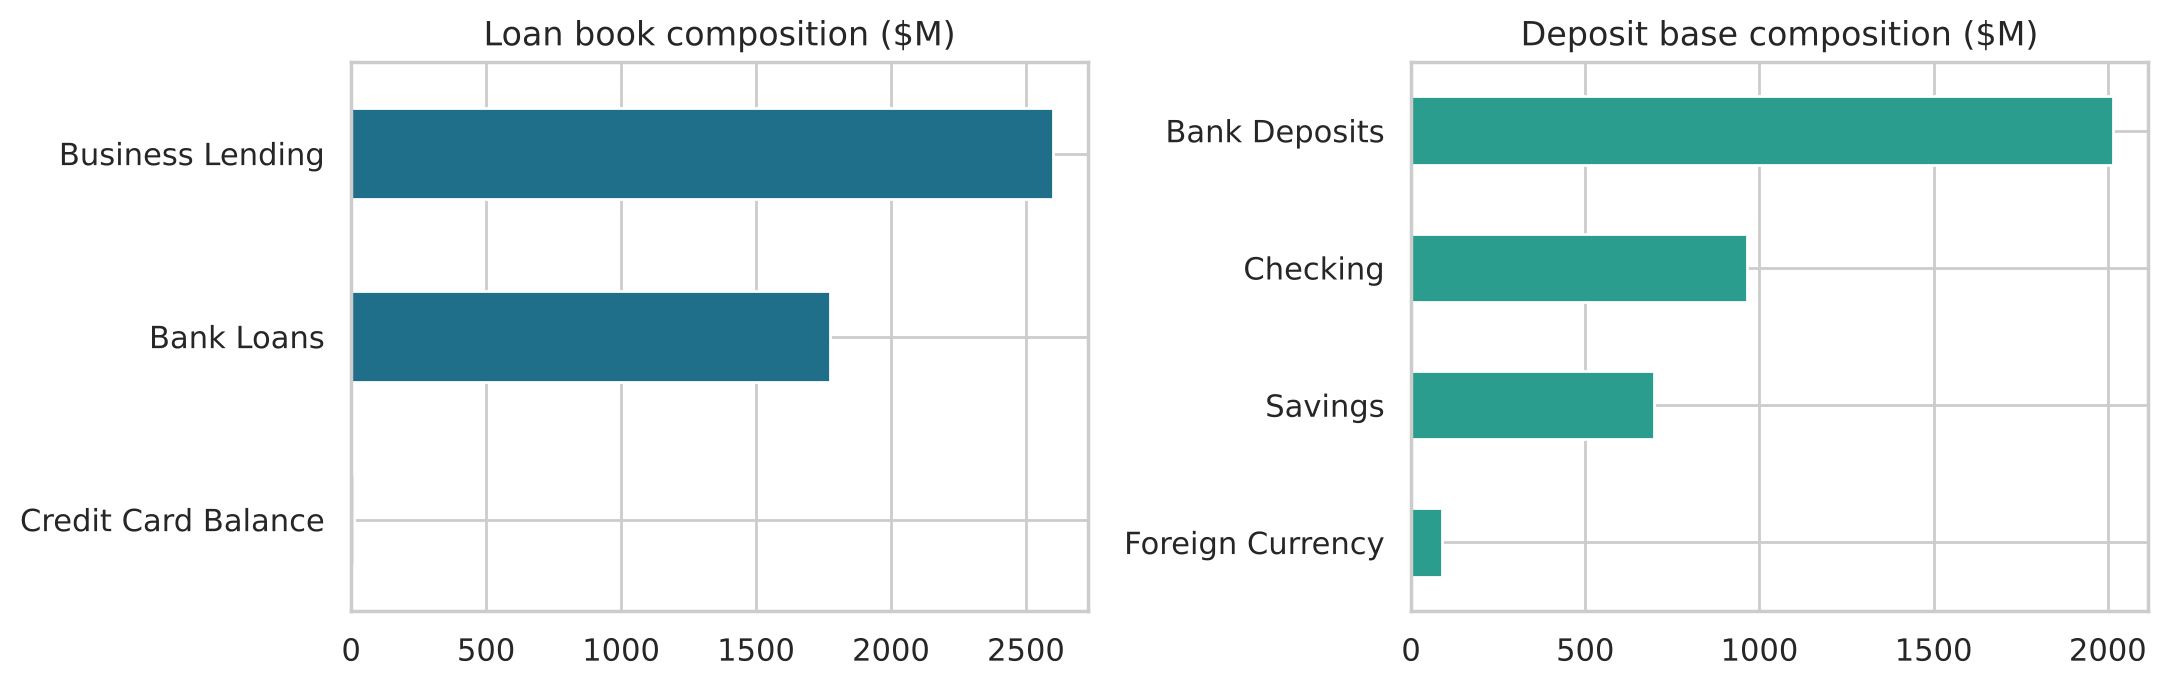

(Bank Loans            0.41
 Business Lending      0.59
 Credit Card Balance   0.00
 dtype: float64,
 Bank Deposits      0.54
 Checking           0.26
 Savings            0.19
 Foreign Currency   0.02
 dtype: float64)

In [3]:
mix = pd.Series({"Bank Loans": df.bank_loans.sum(), "Business Lending": df.business_lending.sum(),
                 "Credit Card Balance": df.credit_card_balance.sum()}) / M
dep = pd.Series({"Bank Deposits": df.bank_deposits.sum(), "Checking": df.checking_accounts.sum(),
                 "Savings": df.saving_accounts.sum(), "Foreign Currency": df.foreign_currency_account.sum()}) / M
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
mix.sort_values().plot.barh(ax=ax[0], color="#1f6f8b"); ax[0].set_title("Loan book composition ($M)")
dep.sort_values().plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].set_title("Deposit base composition ($M)")
save("01_loan_deposit_mix.png")
(mix / mix.sum()).round(3), (dep / dep.sum()).round(3)

## 2. Who holds the loans and deposits?

In [4]:
def profile(col):
    g = df.groupby(col, observed=True).agg(clients=("client_key", "count"),
        total_loan_M=("total_loan", lambda s: s.sum() / M), total_deposit_M=("total_deposit", lambda s: s.sum() / M),
        median_income=("estimated_income", "median"), median_loan_to_income=("loan_to_income", "median"))
    g["share_of_clients"] = g.clients / g.clients.sum()
    g["share_of_loans"] = g.total_loan_M / g.total_loan_M.sum()
    g["loan_to_deposit"] = g.total_loan_M / g.total_deposit_M
    return g.sort_values("total_loan_M", ascending=False)
profile("banking_relationship")

,clients,total_loan_M,total_deposit_M,median_income,median_loan_to_income,share_of_clients,share_of_loans,loan_to_deposit
banking_relationship,,,,,,,,
Private Bank,1352,"1,989.82","1,725.73","140,131.85",3.44,0.45,0.45,1.15
Retail,660,950.40,801.90,"140,013.27",3.34,0.22,0.22,1.19
Commercial,493,731.16,623.40,"157,179.58",3.29,0.16,0.17,1.17
Institutional,495,712.59,615.30,"143,704.18",3.29,0.17,0.16,1.16


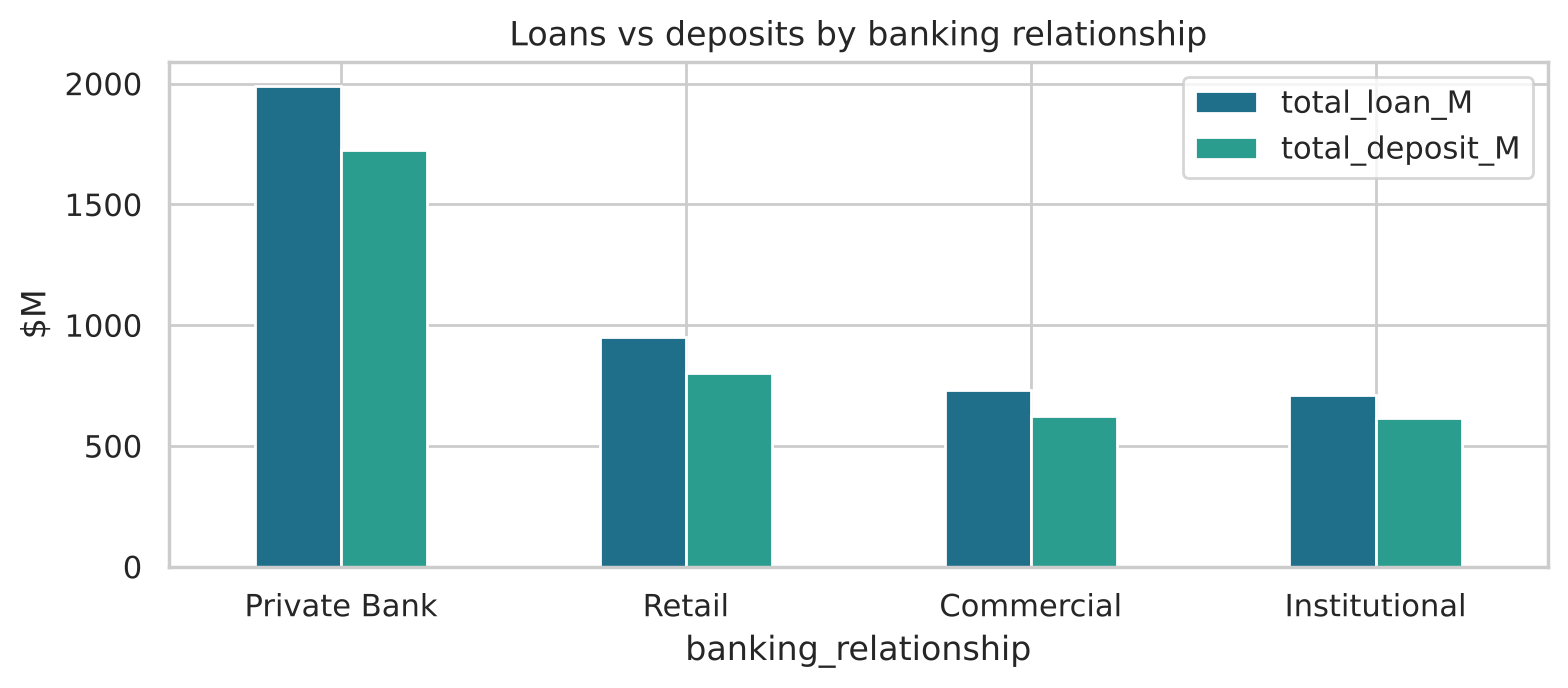

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
p = profile("banking_relationship")[["total_loan_M", "total_deposit_M"]]
p.plot.bar(ax=ax, color=["#1f6f8b", "#2a9d8f"], rot=0); ax.set_ylabel("$M"); ax.set_title("Loans vs deposits by banking relationship")
save("02_relationship_loans_deposits.png")

**Private Bank** clients are about 45% of clients *and* 45% of the loan book, by far the largest single channel. Loan-to-deposit ratios are similar (1.15–1.19) across all four types, so no channel is unusually under-funded.

In [6]:
profile("nationality")

,clients,total_loan_M,total_deposit_M,median_income,median_loan_to_income,share_of_clients,share_of_loans,loan_to_deposit
nationality,,,,,,,,
European,1309,"1,937.67","1,638.71","148,323.72",3.29,0.44,0.44,1.18
Asian,754,"1,084.80",961.28,"137,454.27",3.46,0.25,0.25,1.13
American,507,729.84,630.34,"140,652.04",3.31,0.17,0.17,1.16
Australian,254,382.09,313.67,"130,304.61",3.56,0.08,0.09,1.22
African,176,249.57,222.34,"141,582.23",3.12,0.06,0.06,1.12


In [7]:
profile("income_band")

,clients,total_loan_M,total_deposit_M,median_income,median_loan_to_income,share_of_clients,share_of_loans,loan_to_deposit
income_band,,,,,,,,
Mid,1517,"2,332.93","2,029.76","170,196.21",2.97,0.51,0.53,1.15
Low,1027,"1,103.84",935.33,"66,543.57",5.93,0.34,0.25,1.18
High,456,947.20,801.24,"359,337.98",1.98,0.15,0.22,1.18


In [8]:
profile("age_group")

,clients,total_loan_M,total_deposit_M,median_income,median_loan_to_income,share_of_clients,share_of_loans,loan_to_deposit
age_group,,,,,,,,
60+,1084,"1,586.40","1,362.05","140,402.04",3.29,0.36,0.36,1.16
46-60,666,974.91,841.83,"148,343.77",3.53,0.22,0.22,1.16
31-45,640,962.50,817.31,"145,442.97",3.37,0.21,0.22,1.18
18-30,610,860.17,745.14,"137,075.21",3.27,0.20,0.20,1.15


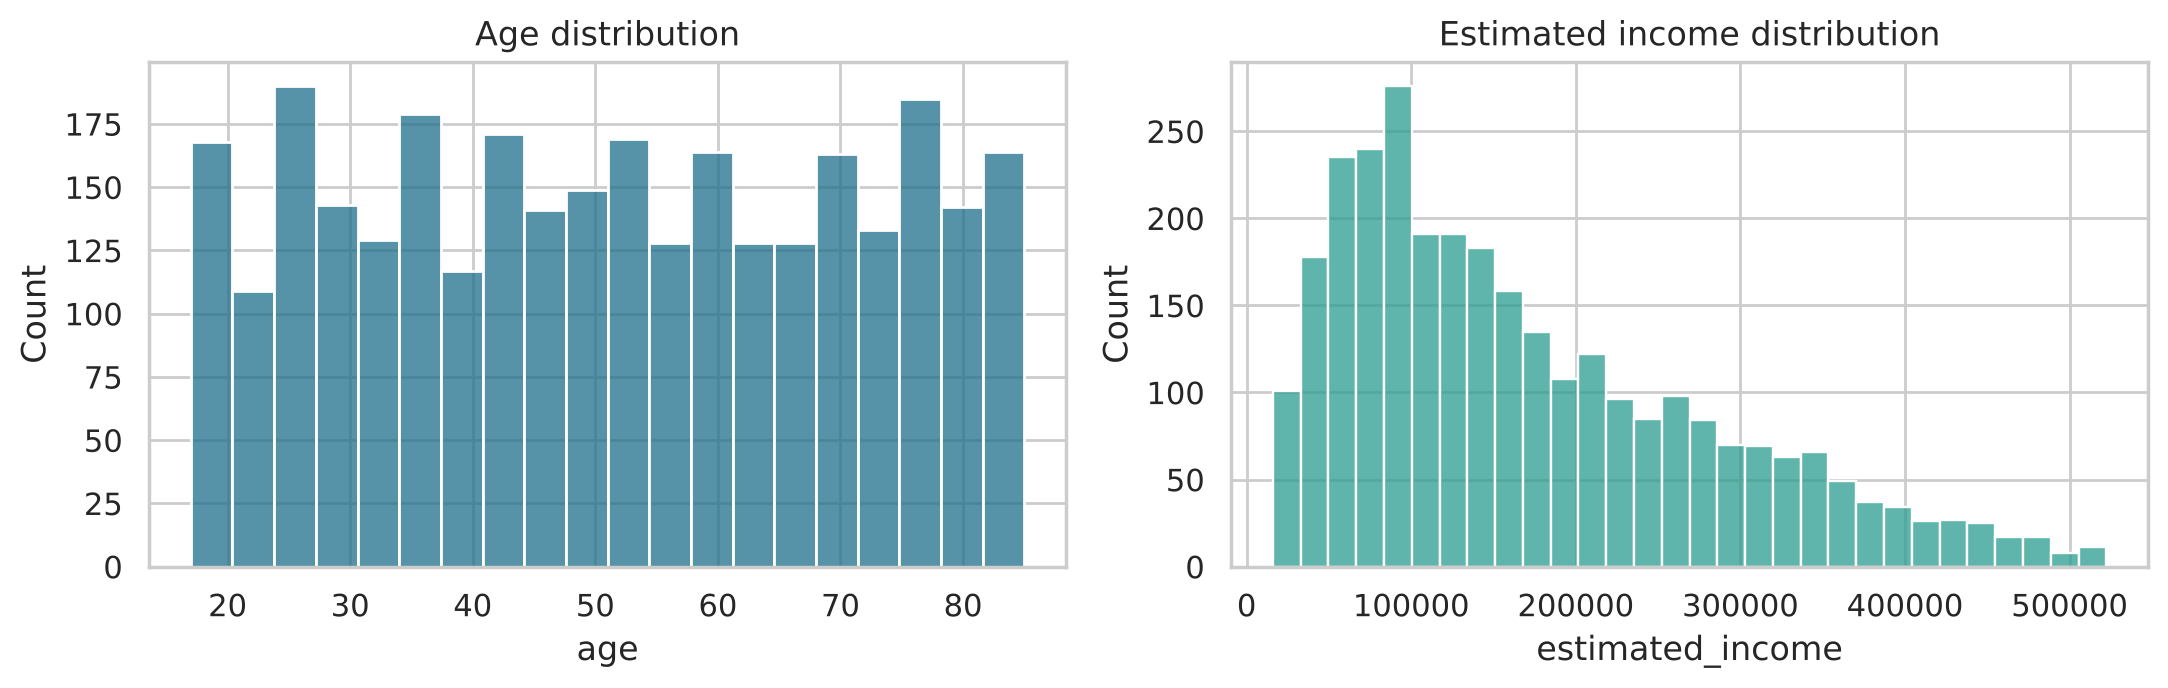

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df.age, bins=20, ax=ax[0], color="#1f6f8b"); ax[0].set_title("Age distribution")
sns.histplot(df.estimated_income, bins=30, ax=ax[1], color="#2a9d8f"); ax[1].set_title("Estimated income distribution")
save("03_age_income_distribution.png")

Clients aged **60+ are the largest age group** (about a third of clients). Income is right-skewed, with most clients in the Mid band.

## 3. Does Risk Weighting capture affordability?

In [10]:
rw = df.groupby("risk_weighting").agg(clients=("client_key", "count"),
        median_income=("estimated_income", "median"), avg_total_loan=("total_loan", "mean"),
        median_loan_to_income=("loan_to_income", "median"),
        pct_loan_over_6x_income=("loan_to_income", lambda s: (s > 6).mean()))
rw

,clients,median_income,avg_total_loan,median_loan_to_income,pct_loan_over_6x_income
risk_weighting,,,,,
1,836,"74,861.84","821,950.67",3.96,0.33
2,1222,"151,522.07","1,442,227.83",3.32,0.26
3,460,"256,053.66","1,933,168.05",3.03,0.22
4,322,"289,627.09","2,103,510.77",2.78,0.19
5,160,"311,787.78","2,298,909.84",2.79,0.16


In [11]:
rho, p = stats.spearmanr(df.estimated_income, df.risk_weighting)
print(f"Spearman correlation, income vs risk weighting: rho = {rho:.2f}, p = {p:.1e}")
rho2, p2 = stats.spearmanr(df.loan_to_income, df.risk_weighting)
print(f"Spearman correlation, loan-to-income vs risk weighting: rho = {rho2:.2f}, p = {p2:.1e}")

Spearman correlation, income vs risk weighting: rho = 0.68, p = 0.0e+00
Spearman correlation, loan-to-income vs risk weighting: rho = -0.13, p = 2.6e-13


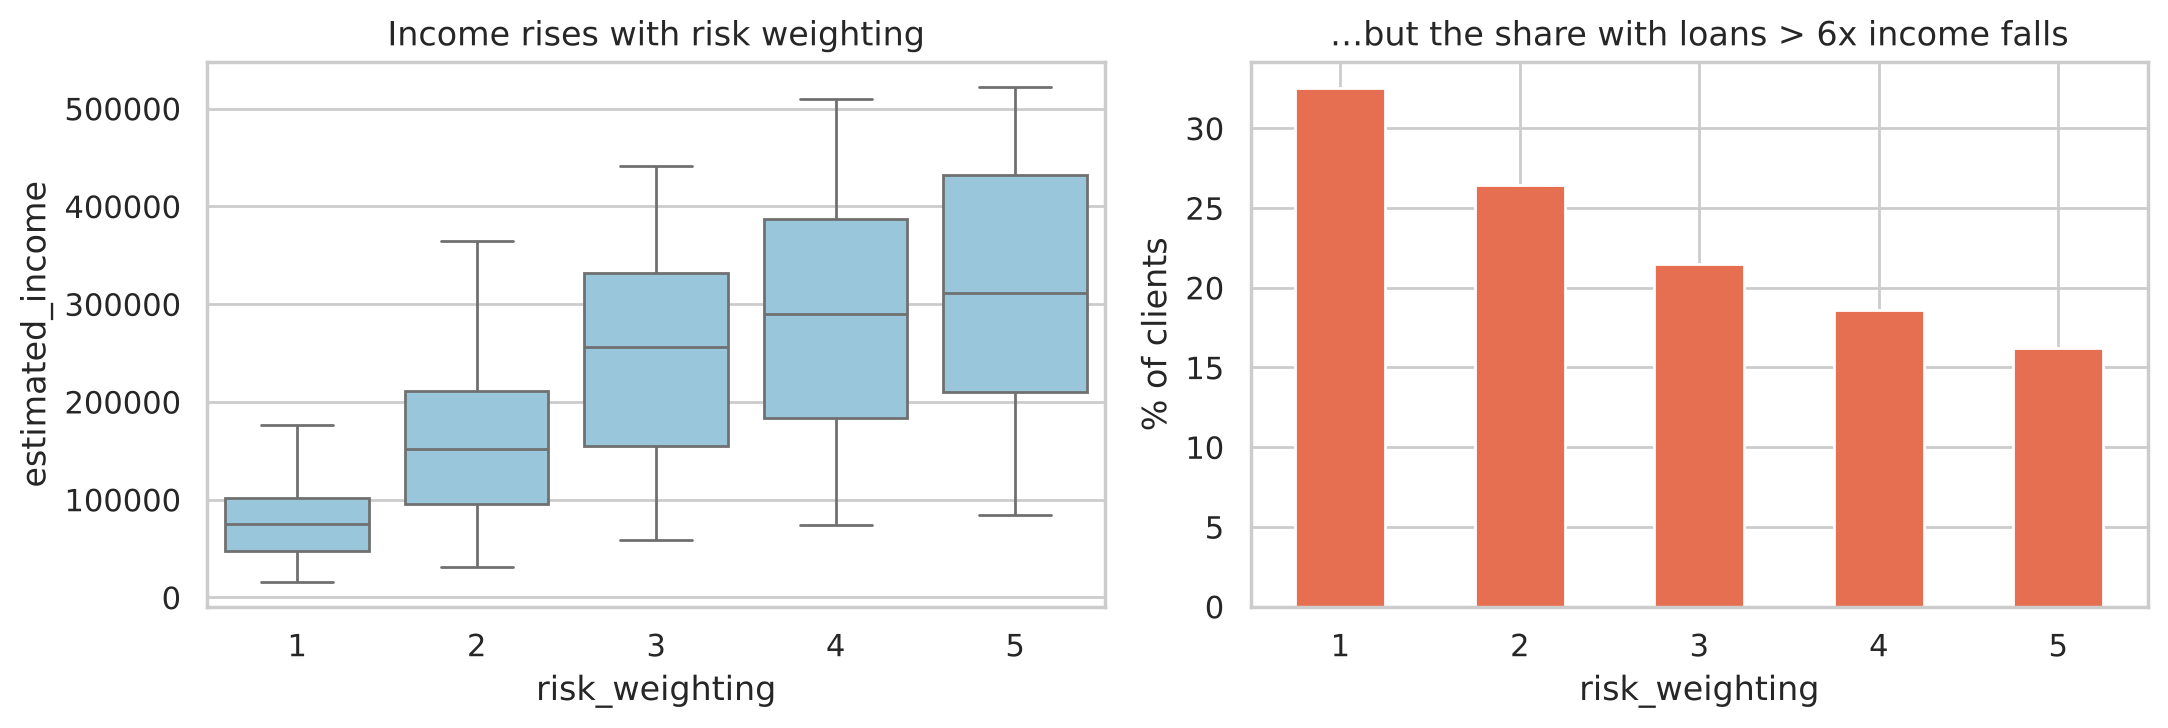

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="risk_weighting", y="estimated_income", ax=ax[0], color="#8ecae6", showfliers=False)
ax[0].set_title("Income rises with risk weighting")
(rw.pct_loan_over_6x_income * 100).plot.bar(ax=ax[1], color="#e76f51", rot=0)
ax[1].set_ylabel("% of clients"); ax[1].set_title("…but the share with loans > 6x income falls")
save("04_risk_weighting_vs_affordability.png")

**Key insight:** Risk Weighting rises strongly with income and exposure size (ρ ≈ 0.68), so it behaves like an *exposure-size* score. It does **not** capture affordability. The share of clients whose bank loan exceeds 6× their income is **highest in the lowest risk band** (about 33% at weight 1 vs about 16% at weight 5).

That creates a blind spot: highly leveraged, lower-income clients are rated "low risk".

In [13]:
flag = df[df.underrated_risk_flag]
print(f"Under-rated risk clients: {len(flag)} ({len(flag)/len(df):.1%} of clients)")
print(f"Their bank loans: ${flag.bank_loans.sum()/M:,.0f}M ({flag.bank_loans.sum()/df.bank_loans.sum():.1%} of all bank loans)")
print(f"Median loan-to-income: {flag.loan_to_income.median():.1f}x vs {df.loan_to_income.median():.1f}x overall")
flag.groupby("banking_relationship").size().sort_values(ascending=False)

Under-rated risk clients: 595 (19.8% of clients)
Their bank loans: $448M (25.3% of all bank loans)
Median loan-to-income: 9.1x vs 3.3x overall


banking_relationship
Private Bank     289
Retail           129
Institutional     89
Commercial        88
dtype: int64

## 4. Does the loyalty programme reflect customer value?

In [14]:
loy = df.groupby("loyalty_classification").agg(clients=("client_key", "count"),
        median_income=("estimated_income", "median"), median_deposit=("total_deposit", "median"),
        median_loan=("total_loan", "median"), avg_tenure=("tenure_years", "mean"))
loy.loc[["Jade", "Silver", "Gold", "Platinum"]]

,clients,median_income,median_deposit,median_loan,avg_tenure
loyalty_classification,,,,,
Jade,1331,"144,947.04","982,944.57","1,242,714.20",11.18
Silver,767,"141,689.81","950,744.98","1,247,938.05",11.83
Gold,585,"139,310.32","889,274.10","1,191,216.66",11.19
Platinum,317,"136,956.20","853,154.08","1,216,289.09",11.47


In [15]:
groups = [g.total_deposit for _, g in df.groupby("loyalty_classification")]
print("Kruskal-Wallis, deposits across loyalty tiers:", stats.kruskal(*groups))
groups = [g.estimated_income for _, g in df.groupby("loyalty_classification")]
print("Kruskal-Wallis, income across loyalty tiers:  ", stats.kruskal(*groups))
groups = [g.tenure_years for _, g in df.groupby("loyalty_classification")]
print("Kruskal-Wallis, tenure across loyalty tiers:  ", stats.kruskal(*groups))

Kruskal-Wallis, deposits across loyalty tiers: KruskalResult(statistic=np.float64(5.204515570816511), pvalue=np.float64(0.15741961683080247))
Kruskal-Wallis, income across loyalty tiers:   KruskalResult(statistic=np.float64(1.8541647791862488), pvalue=np.float64(0.6032195936547704))
Kruskal-Wallis, tenure across loyalty tiers:   KruskalResult(statistic=np.float64(4.7319961420680094), pvalue=np.float64(0.19250697882474246))


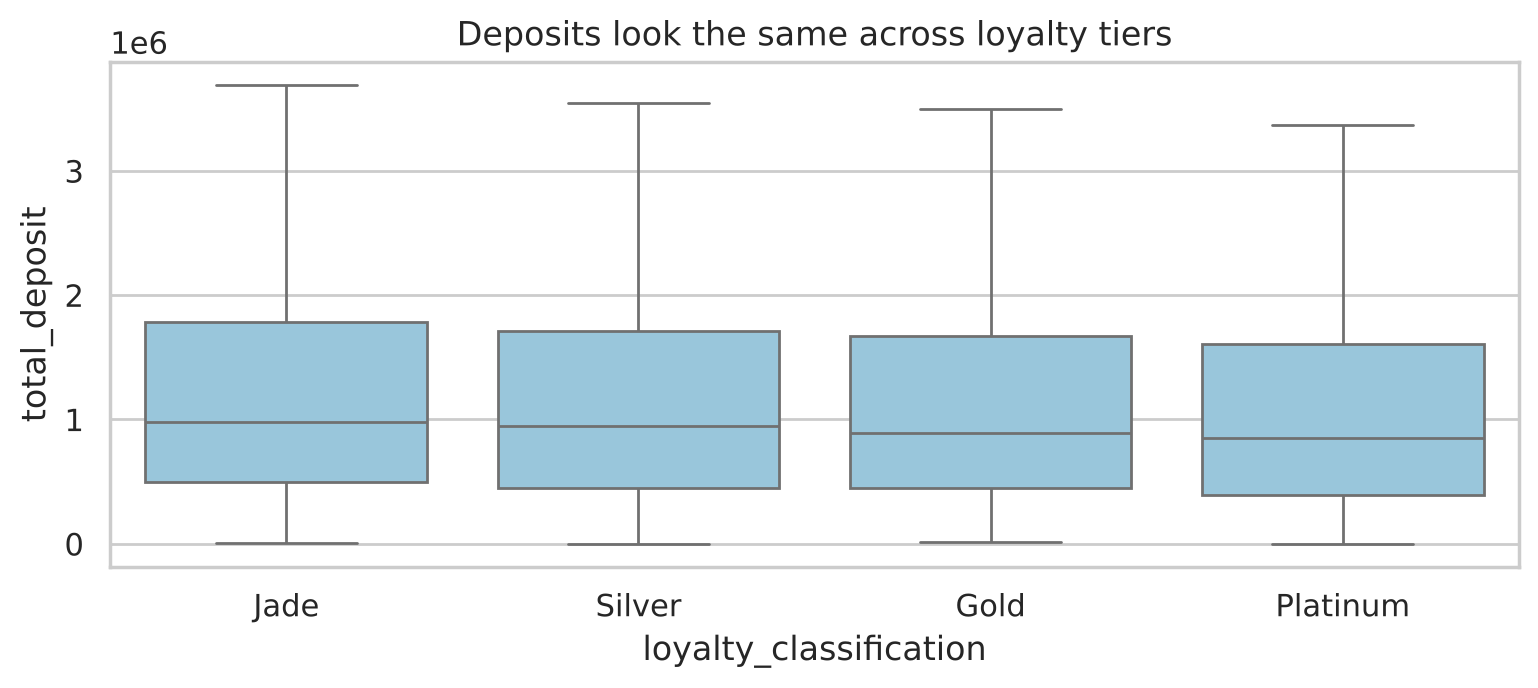

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.boxplot(data=df, x="loyalty_classification", y="total_deposit", order=["Jade", "Silver", "Gold", "Platinum"],
            showfliers=False, color="#8ecae6", ax=ax)
ax.set_title("Deposits look the same across loyalty tiers"); save("05_loyalty_vs_deposits.png")

**Insight:** there is **no statistically significant difference** in deposits, income or tenure across Jade/Silver/Gold/Platinum (all Kruskal–Wallis p > 0.05). The loyalty tiers don't reflect customer value, so rewards may be going to the wrong clients. **Recommendation:** re-base tiers on deposit balance, product holding and tenure.

## 5. Fee structure

In [17]:
df.groupby("fee_structure").agg(clients=("client_key", "count"), median_income=("estimated_income", "median"),
    median_loan=("total_loan", "median"), fee_revenue_M=("est_fee_revenue", lambda s: s.sum() / M))

,clients,median_income,median_loan,fee_revenue_M
fee_structure,,,,
High,1476,"145,040.17","1,248,117.23",107.10
Low,562,"140,979.78","1,235,081.46",8.08
Mid,962,"139,856.19","1,195,958.45",43.01


About half the clients are on the **High** fee structure, and fee tier isn't linked to income or loan size. High-fee clients generate most of the estimated fee revenue, but that also makes them the price-sensitive group most exposed to switching to competitors.

## 6. Relationship segments (product mix)

In [18]:
seg = df.groupby("relationship_segment").agg(clients=("client_key", "count"),
        total_loan_M=("total_loan", lambda s: s.sum() / M), total_deposit_M=("total_deposit", lambda s: s.sum() / M),
        median_income=("estimated_income", "median"), avg_risk_weight=("risk_weighting", "mean"))
seg["share_of_clients"] = seg.clients / len(df)
seg.sort_values("total_loan_M", ascending=False)

,clients,total_loan_M,total_deposit_M,median_income,avg_risk_weight,share_of_clients
relationship_segment,,,,,,
Full relationship,1009,"2,279.17","2,249.36","191,665.95",2.77,0.34
Borrower-heavy,491,973.35,253.83,"170,020.82",2.59,0.16
Low engagement,1009,709.46,459.68,"95,819.67",1.62,0.34
Saver,491,421.99,803.46,"135,831.23",2.13,0.16


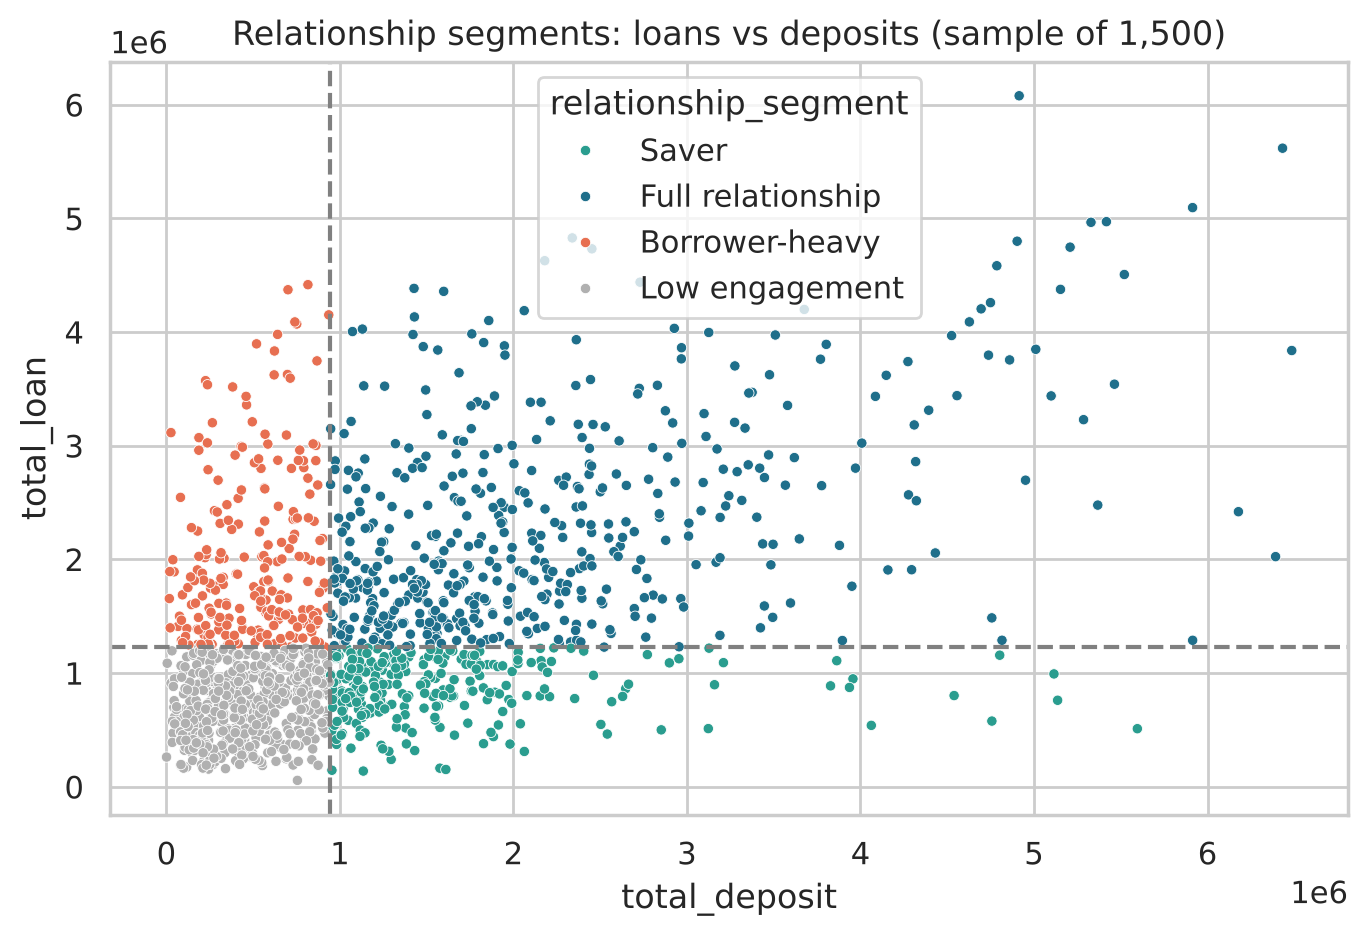

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
sample = df.sample(1500, random_state=7)
sns.scatterplot(data=sample, x="total_deposit", y="total_loan", hue="relationship_segment", s=14, ax=ax,
                palette={"Full relationship": "#1f6f8b", "Borrower-heavy": "#e76f51", "Saver": "#2a9d8f", "Low engagement": "#b0b0b0"})
ax.axvline(df.total_deposit.median(), ls="--", c="grey"); ax.axhline(df.total_loan.median(), ls="--", c="grey")
ax.set_title("Relationship segments: loans vs deposits (sample of 1,500)"); save("06_relationship_segments.png")

- **Borrower-heavy** clients (above-median loans, below-median deposits) are the funding-gap drivers. They are the target for **deposit cross-sell**.
- **Savers** (high deposits, low loans) are the target for **lending/investment products**.
- **Full-relationship** clients are the most valuable and should be prioritised for retention.

## 7. Investment-advisor portfolios

In [20]:
ia = df.groupby("investment_advisor").agg(clients=("client_key", "count"),
        total_loan_M=("total_loan", lambda s: s.sum() / M), underrated_risk_clients=("underrated_risk_flag", "sum"))
ia["share_of_loans"] = ia.total_loan_M / ia.total_loan_M.sum()
ia.sort_values("total_loan_M", ascending=False).head(8)

,clients,total_loan_M,underrated_risk_clients,share_of_loans
investment_advisor,,,,
Peter Castillo,176,291.63,22,0.07
Daniel Carroll,176,276.65,32,0.06
Ernest Knight,177,267.86,35,0.06
Lawrence Sanchez,176,262.54,33,0.06
Victor Dean,177,260.62,28,0.06
Joe Carroll,177,259.55,44,0.06
Jeremy Porter,177,259.04,39,0.06
Carl Anderson,176,250.04,37,0.06


Advisor books range from about 88 to 177 clients. No single advisor manages more than about 7% of the loan book, so there's no key-person concentration risk.

## 8. Correlations

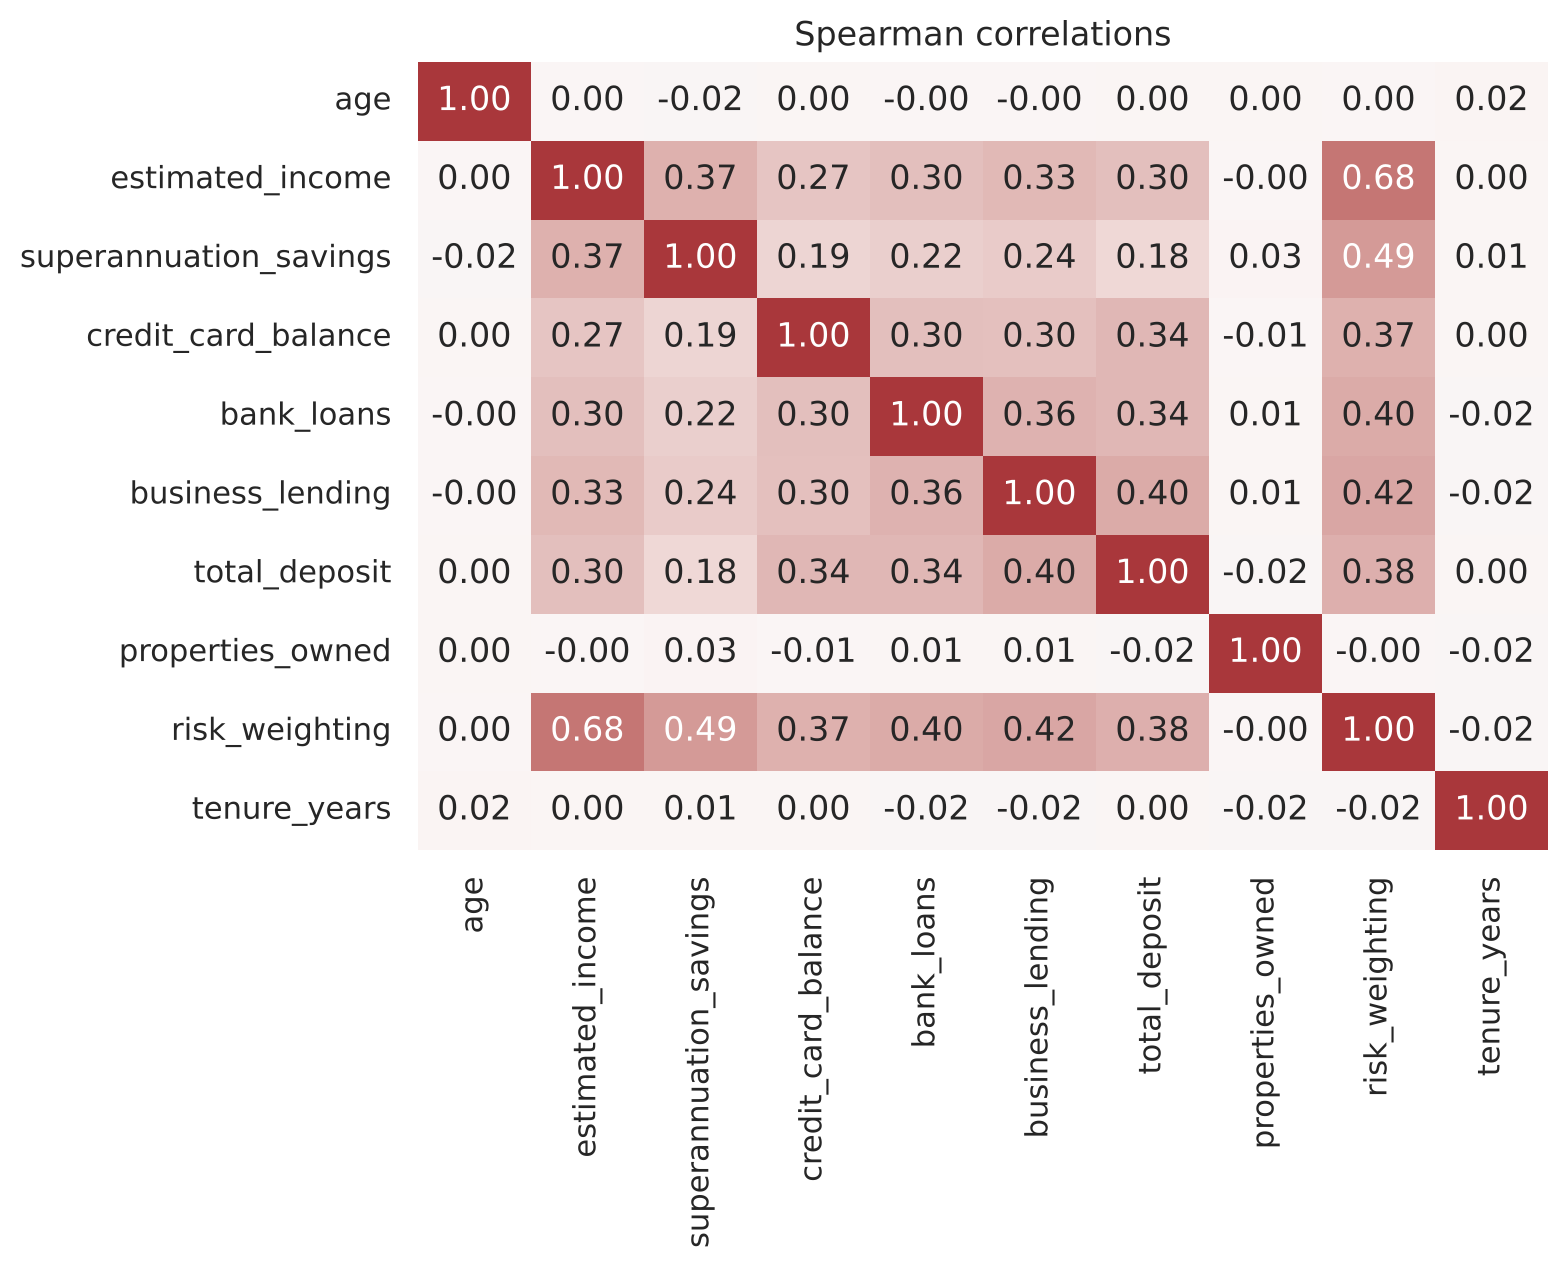

In [21]:
num = ["age", "estimated_income", "superannuation_savings", "credit_card_balance", "bank_loans", "business_lending",
       "total_deposit", "properties_owned", "risk_weighting", "tenure_years"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[num].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar=False)
ax.set_title("Spearman correlations"); save("07_correlations.png")

Income is the strongest correlate of risk weighting and of every balance. **Age, tenure and properties owned are essentially uncorrelated** with balances, so older or longer-tenured clients aren't automatically more valuable.

## Summary of findings → see `docs/insights_report.md`